In [44]:
%pip install seaborn


In [64]:
import pandas
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [47]:
df=pandas.read_csv("train.csv")

In [48]:
rowCols=df.shape
print(rowCols)
print(df.head())
print(df.info())

totalMissing=df.isnull().sum()
print(totalMissing)
    


(1460, 81)
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType  SaleCondition  SalePrice  
0   2008  

In [49]:
totalMissing=df.isnull().sum()
print(totalMissing)

print(totalMissing[totalMissing>0])

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64
LotFrontage      259
Alley           1369
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64


In [52]:
numerical = df.select_dtypes(include='number')

categorial=df.select_dtypes(include='object')

ordinal = {
"ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
"KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"]
}
for column in ordinal:
    df[column] = pandas.Categorical(
        df[column],
        categories=ordinal[column],
        ordered=True
    )

<ipython-input-52-10c71ad28148>:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorial=df.select_dtypes(include='object')


In [54]:
print(numerical.describe())
for column in numerical[['SalePrice', 'GrLivArea', 'LotArea']]:
    print("column name: ", column)
    mean=df[column].mean()
    median=df[column].median();
    mode=df[column].mode();
    std = df[column].std()
    var = df[column].var()
    range_value = df[column].max() - df[column].min()
    
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3-Q1

    skew = df[column].skew()
    kurt = df[column].kurt()
    
    print("mean " ,mean)
    print("mode ", mode)
    print("median ",median)
    print("std " ,std)
    print("variance " ,var)
    print("range_value " ,range_value)
    print("IQR ", IQR);
    print("skew " ,skew)
    print("kurt ",kurt)

    if(mean>median):
        print("right skewed")
    elif (mean<median):
        print("left skewed")


for column in ['Neighborhood', 'HouseStyle']:
    print(df[column].value_counts())

                Id   MSSubClass  LotFrontage        LotArea  OverallQual  \
count  1460.000000  1460.000000  1201.000000    1460.000000  1460.000000   
mean    730.500000    56.897260    70.049958   10516.828082     6.099315   
std     421.610009    42.300571    24.284752    9981.264932     1.382997   
min       1.000000    20.000000    21.000000    1300.000000     1.000000   
25%     365.750000    20.000000    59.000000    7553.500000     5.000000   
50%     730.500000    50.000000    69.000000    9478.500000     6.000000   
75%    1095.250000    70.000000    80.000000   11601.500000     7.000000   
max    1460.000000   190.000000   313.000000  215245.000000    10.000000   

       OverallCond    YearBuilt  YearRemodAdd   MasVnrArea   BsmtFinSF1  ...  \
count  1460.000000  1460.000000   1460.000000  1452.000000  1460.000000  ...   
mean      5.575342  1971.267808   1984.865753   103.685262   443.639726  ...   
std       1.112799    30.202904     20.645407   181.066207   456.098091  ..

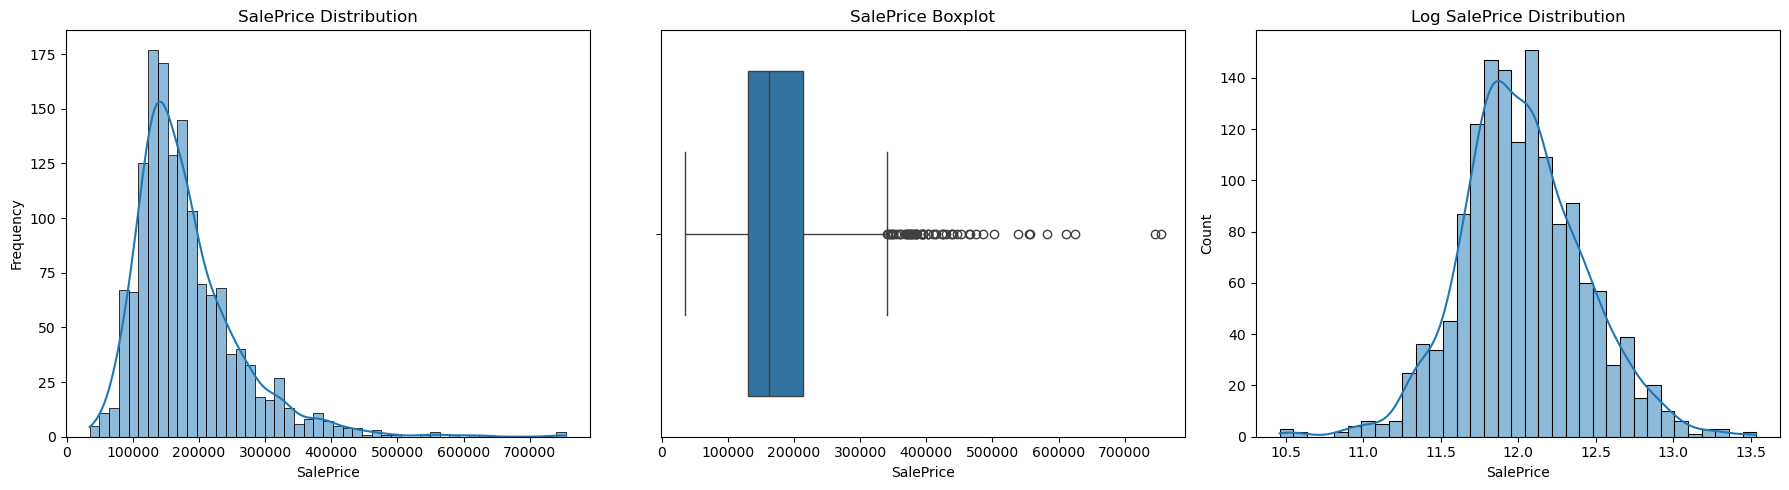

In [65]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(df['SalePrice'], kde=True, ax=axes[0])
axes[0].set_title("SalePrice Distribution")
axes[0].set_xlabel("SalePrice")
axes[0].set_ylabel("Frequency")
sns.boxplot(x=df['SalePrice'], ax=axes[1])
axes[1].set_title("SalePrice Boxplot")
sns.histplot(np.log1p(df['SalePrice']), kde=True, ax=axes[2])
axes[2].set_title("Log SalePrice Distribution")

plt.tight_layout()
plt.show()

In [66]:
print("Original skewness:", df['SalePrice'].skew())
print("Log skewness:", np.log1p(df['SalePrice']).skew())

Original skewness: 1.8828757597682129
Log skewness: 0.12134661989685333


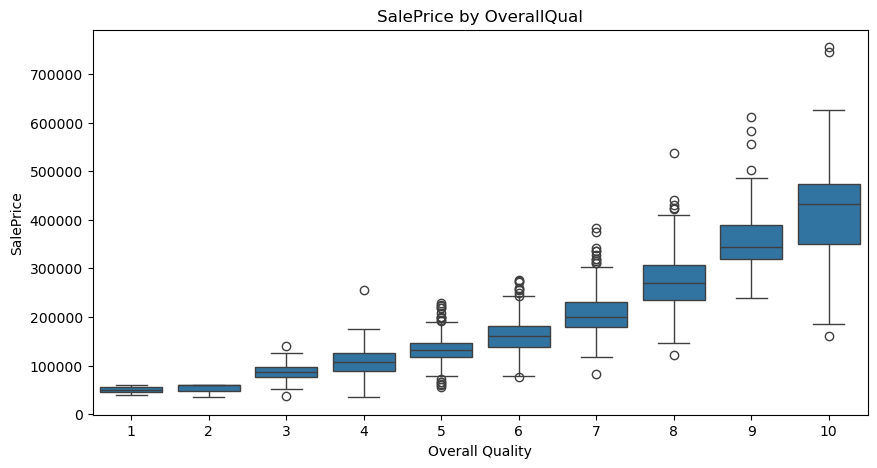

In [67]:
plt.figure(figsize=(10, 5))
sns.boxplot(x='OverallQual', y='SalePrice', data=df)
plt.title("SalePrice by OverallQual")
plt.xlabel("Overall Quality")
plt.ylabel("SalePrice")
plt.show()

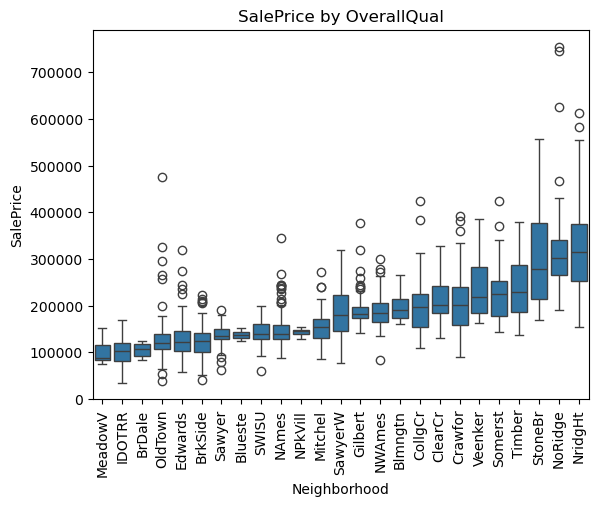

In [70]:
order = df.groupby('Neighborhood')['SalePrice'].median().sort_values().index
sns.boxplot(x='Neighborhood', y='SalePrice',data=df,order=order)

plt.xticks(rotation=90)

plt.title("SalePrice by OverallQual")
plt.xlabel("Neighborhood")
plt.ylabel("SalePrice")
plt.show()

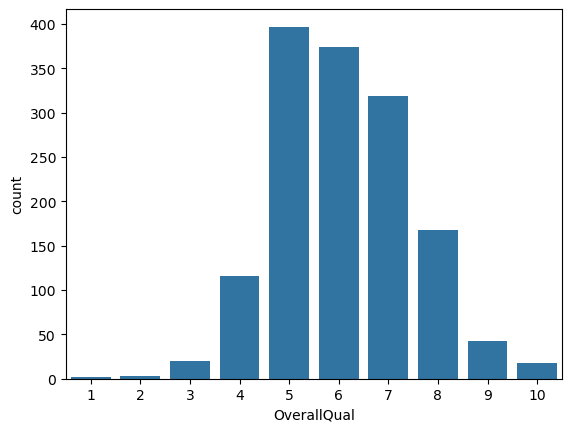

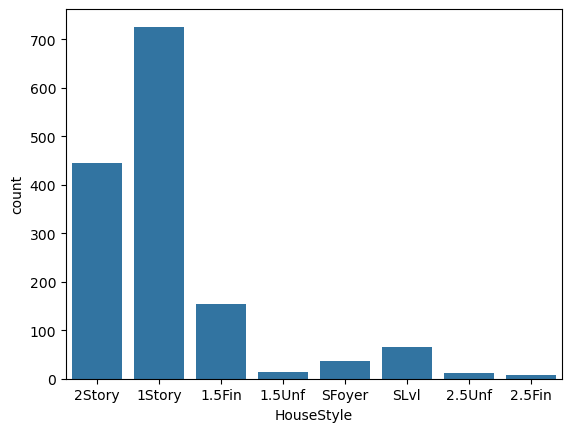

In [72]:
sns.countplot(x='OverallQual', data=df)
plt.show()

sns.countplot(x='HouseStyle', data=df)
plt.show()

In [73]:
cov_matrix = numerical.cov()
corr_matrix = numerical.corr(method='pearson')
top_corr = corr_matrix['SalePrice'].abs().sort_values(ascending=False)

print(top_corr.head(10))

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
Name: SalePrice, dtype: float64


In [ ]:
top_3 = top_corr.head(3).index

for column in top_3:
    print("Feature:", column)
    print("Covariance:", cov_matrix.loc[column, 'SalePrice'])
    print("Correlation:", corr_matrix.loc[column, 'SalePrice'])

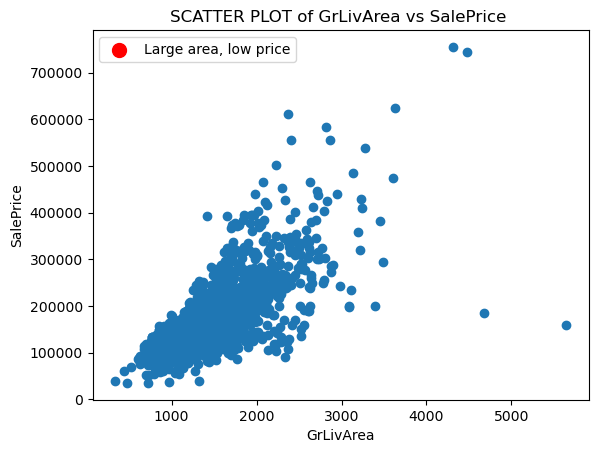

In [78]:
plt.scatter(df['GrLivArea'],df['SalePrice'])
plt.title("SCATTER PLOT of GrLivArea vs SalePrice ")
plt.xlabel("GrLivArea")
plt.ylabel("SalePrice")
outliers = df[(df['GrLivArea'] > 4000) & (df['SalePrice'] < df['SalePrice'].quantile(0.25))]
plt.scatter(outliers['GrLivArea'], outliers['SalePrice'], color='red')
plt.show()

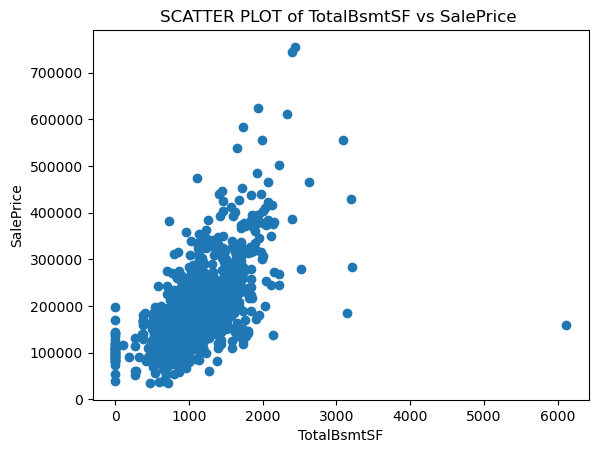

In [79]:
plt.scatter(df['TotalBsmtSF'],df['SalePrice'])
plt.title("SCATTER PLOT of TotalBsmtSF vs SalePrice ")
plt.xlabel("TotalBsmtSF")
plt.ylabel("SalePrice")

plt.show()

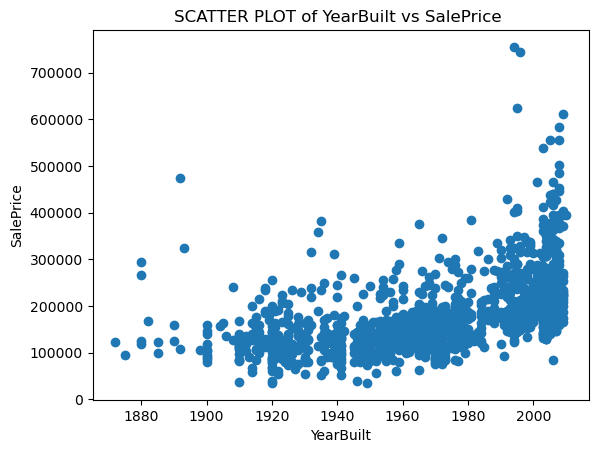

In [80]:
plt.scatter(df['YearBuilt'],df['SalePrice'])
plt.title("SCATTER PLOT of YearBuilt vs SalePrice ")
plt.xlabel("YearBuilt")
plt.ylabel("SalePrice")

plt.show()

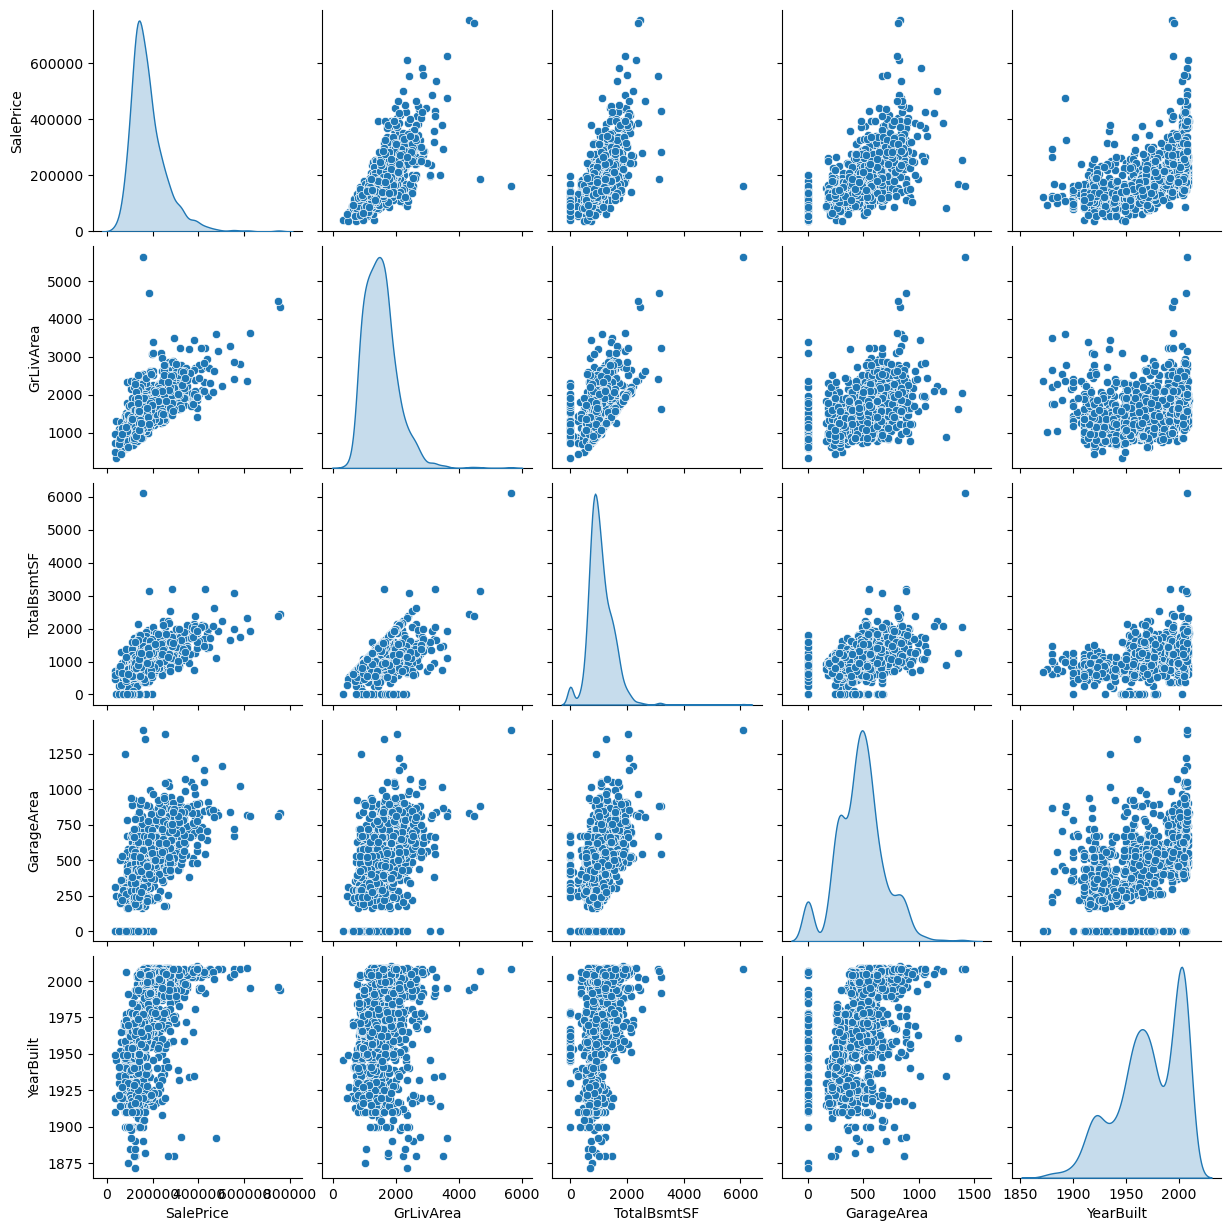

In [81]:
selected = ['SalePrice', 'GrLivArea', 'TotalBsmtSF', 'GarageArea', 'YearBuilt']

sns.pairplot(df[selected], diag_kind='kde')
plt.show()

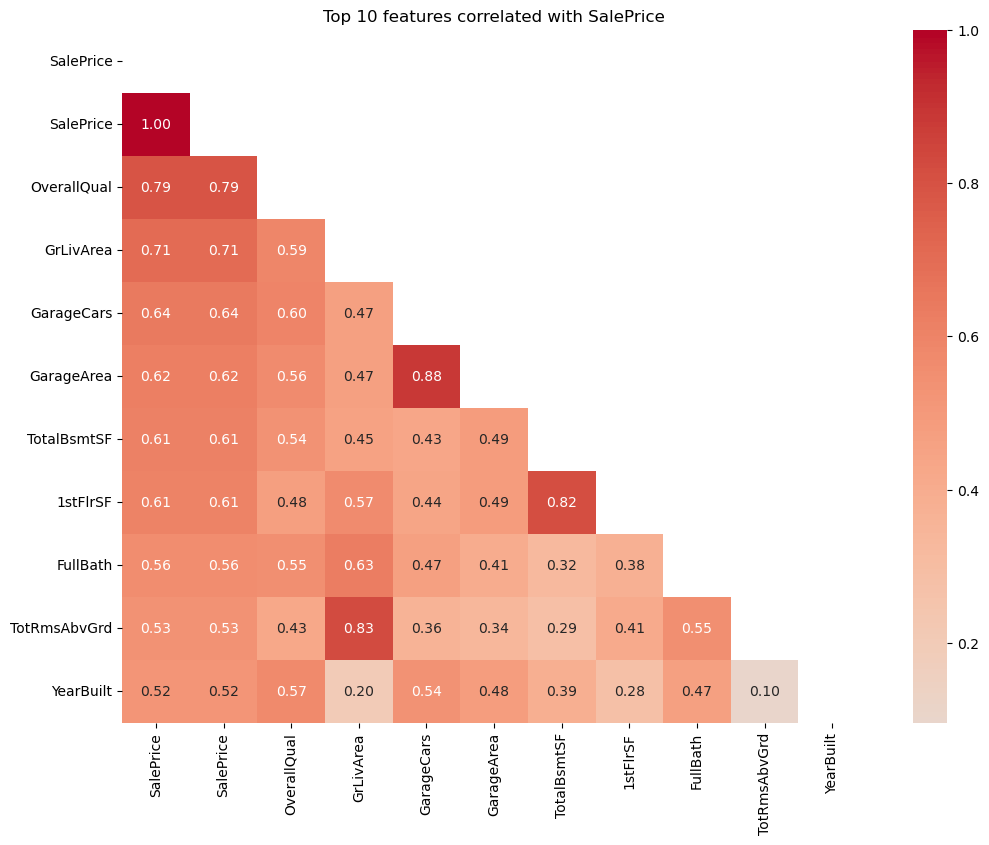

In [82]:
top10 = top_corr.head(10).index
corr_top = df[top10].corr()
top10 = ['SalePrice'] + list(top_corr.head(10).index)
corr_top = df[top10].corr()
mask = np.triu(np.ones_like(corr_top, dtype=bool))
plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_top,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    mask=mask
)

plt.title("Top 10 features correlated with SalePrice")
plt.show()

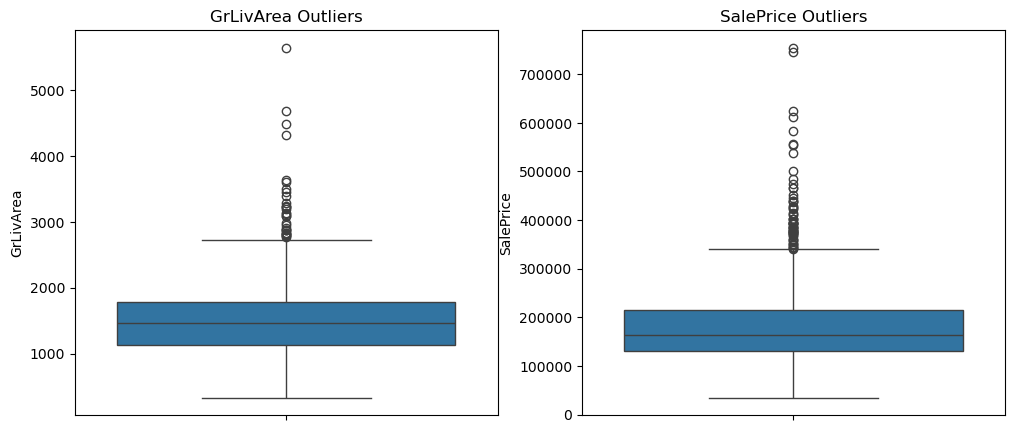

In [90]:
def iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return df[(series < lower) | (series > upper)]
    

def zscore_outliers(series, threshold=3):
    z = (series - series.mean()) / series.std()
    return df[abs(z) > threshold]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df['GrLivArea'], ax=axes[0])
axes[0].set_title('GrLivArea Outliers')

sns.boxplot(y=df['SalePrice'], ax=axes[1])
axes[1].set_title('SalePrice Outliers')
plt.show()




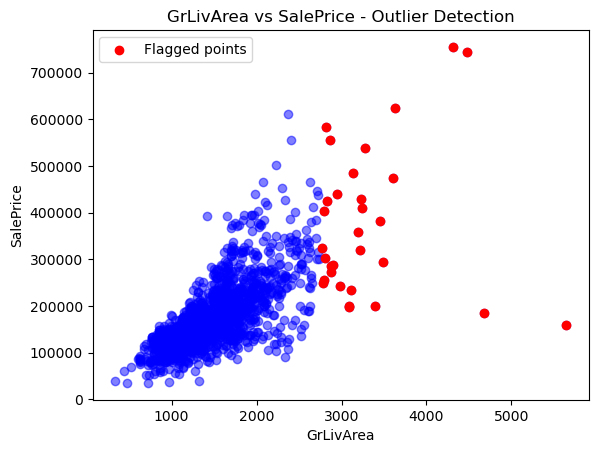

In [91]:

a = iqr_outliers(df['GrLivArea'])
b = zscore_outliers(df['GrLivArea'])

flagged = a.index.union(b.index)

plt.scatter(df['GrLivArea'], df['SalePrice'], color='blue', alpha=0.5)

plt.scatter(
    df.loc[flagged, 'GrLivArea'],
    df.loc[flagged, 'SalePrice'],
    color='red',
    label='Flagged points'
)

plt.xlabel('GrLivArea')
plt.ylabel('SalePrice')
plt.title('GrLivArea vs SalePrice - Outlier Detection')
plt.legend()
plt.show()

In [92]:
suspicious = df[
    (df['GrLivArea'] > 4000) &
    (df['SalePrice'] < 300000)
]

print(suspicious[['GrLivArea', 'SalePrice']])
df_clean = df.drop(suspicious.index).copy()
df_clean = df.copy()
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

      GrLivArea  SalePrice
523        4676     184750
1298       5642     160000
Original shape: (1460, 81)
Cleaned shape: (1460, 81)


In [93]:
dup_count = df.duplicated().sum()

print("Duplicate rows:", dup_count)

if dup_count > 0:
    df = df.drop_duplicates()
    print("New shape:", df.shape)


categorical_cols = df.select_dtypes(include='object').columns

for column in categorical_cols:
    print("\nColumn:", column)
    print("Unique values:", df[column].unique())

    # Remove extra spaces and standardise casing
    df[column] = df[column].str.strip().str.lower()


cols_none = ['PoolQC', 'Alley', 'Fence', 'FireplaceQu', 'GarageType']

for column in cols_none:
    df[column] = df[column].fillna('none')



df['LotFrontage'] = df.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median())
)

df['LotFrontage'] = df['LotFrontage'].fillna(df['LotFrontage'].median())


print("\nMissing values in each column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("Total remaining missing values:", df.isnull().sum().sum())


invalid_years = df[df['YearBuilt'] > df['YrSold']]

print("\nRows where YearBuilt > YrSold:")
print(invalid_years[['YearBuilt', 'YrSold']])

area_cols = ['GrLivArea', 'TotalBsmtSF', 'GarageArea', 'LotArea']

for column in area_cols:
    print("Negative values in", column, ":", (df[column] < 0).sum())


print("\nFinal dataset shape:", df.shape)
print("Duplicate rows remaining:", df.duplicated().sum())


Duplicate rows: 0


<ipython-input-93-3d6cd7082b3f>:14: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include='object').columns



Column: MSZoning
Unique values: <StringArray>
['RL', 'RM', 'C (all)', 'FV', 'RH']
Length: 5, dtype: str

Column: Street
Unique values: <StringArray>
['Pave', 'Grvl']
Length: 2, dtype: str

Column: Alley
Unique values: <StringArray>
[nan, 'Grvl', 'Pave']
Length: 3, dtype: str

Column: LotShape
Unique values: <StringArray>
['Reg', 'IR1', 'IR2', 'IR3']
Length: 4, dtype: str

Column: LandContour
Unique values: <StringArray>
['Lvl', 'Bnk', 'Low', 'HLS']
Length: 4, dtype: str

Column: Utilities
Unique values: <StringArray>
['AllPub', 'NoSeWa']
Length: 2, dtype: str

Column: LotConfig
Unique values: <StringArray>
['Inside', 'FR2', 'Corner', 'CulDSac', 'FR3']
Length: 5, dtype: str

Column: LandSlope
Unique values: <StringArray>
['Gtl', 'Mod', 'Sev']
Length: 3, dtype: str

Column: Neighborhood
Unique values: <StringArray>
['CollgCr', 'Veenker', 'Crawfor', 'NoRidge', 'Mitchel', 'Somerst',  'NWAmes',
 'OldTown', 'BrkSide',  'Sawyer', 'NridgHt',   'NAmes', 'SawyerW',  'IDOTRR',
 'MeadowV', 'Edwar